In [3]:
!pip install ultralytics


[notice] A new release of pip is available: 25.2 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import os
import random
import pandas as pd
from PIL import Image
import cv2
from ultralytics import YOLO
from IPython.display import Video
import numpy as np  
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style='darkgrid')
import pathlib
import glob
from tqdm.notebook import trange, tqdm
import warnings
warnings.filterwarnings('ignore')

In [5]:
sns.set(rc={'axes.facecolor': '#eae8fa'}, style='darkgrid')

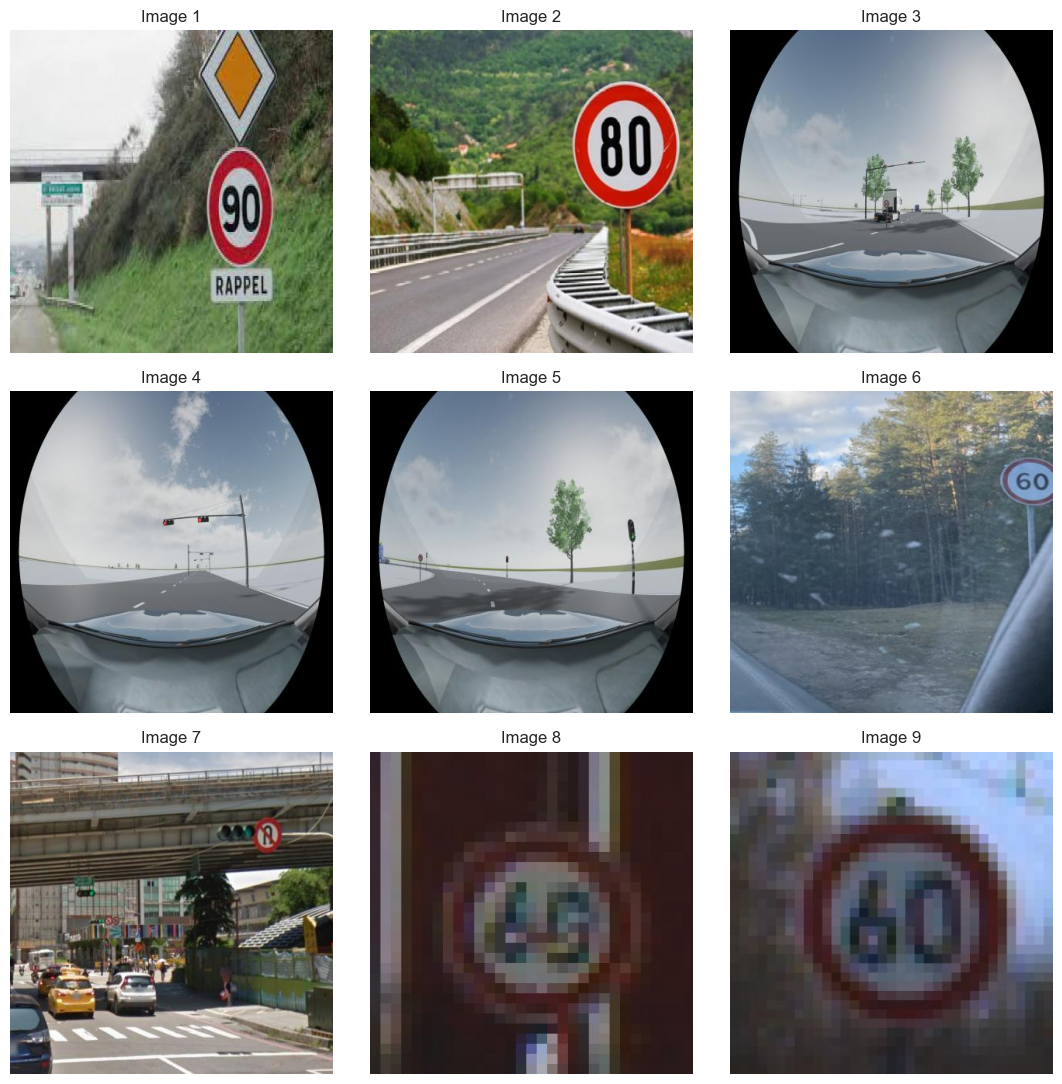

In [ ]:
Image_dir =r"C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\car\train\images"

num_samples = 9
image_files = os.listdir(Image_dir)

#selectare imagini random
rand_images = random.sample(image_files, num_samples)

fig, axes = plt.subplots(3, 3, figsize=(11, 11))

for i in range(num_samples):
    image = rand_images[i]
    ax = axes[i // 3, i % 3]
    ax.imshow(plt.imread(os.path.join(Image_dir, image)))
    ax.set_title(f'Image {i+1}')
    ax.axis('off')

plt.tight_layout()
plt.show()

In [7]:
image = cv2.imread(r"C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\car\train\images\00000_00000_00005_png.rf.998f471ba534c1f2ccafdafcd63c12a4.jpg")
h, w, c = image.shape
print(f"The image has dimensions {w}x{h} and {c} channels.")

The image has dimensions 416x416 and 3 channels.



image 1/1 C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\car\train\images\FisheyeCamera_1_00234_png.rf.bc02f13c5c374934d9648cd70eae24b1.jpg: 640x640 1 truck, 227.1ms
Speed: 33.9ms preprocess, 227.1ms inference, 4.7ms postprocess per image at shape (1, 3, 640, 640)


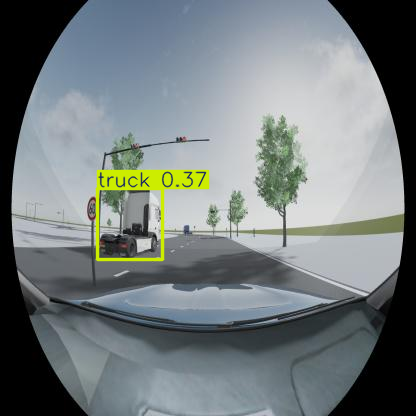

In [8]:
model = YOLO("yolov8n.pt") 

image = r"C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\car\train\images\FisheyeCamera_1_00234_png.rf.bc02f13c5c374934d9648cd70eae24b1.jpg"
result_predict = model.predict(source = image, imgsz=(640))

plot = result_predict[0].plot()
plot = cv2.cvtColor(plot, cv2.COLOR_BGR2RGB)
display(Image.fromarray(plot))

In [9]:
!pip install --upgrade ultralytics ray

ERROR: Ignored the following versions that require a different python version: 8.0.10 Requires-Python >=3.7,<=3.11; 8.0.11 Requires-Python >=3.7,<=3.11; 8.0.12 Requires-Python >=3.7,<=3.11; 8.0.13 Requires-Python >=3.7,<=3.11; 8.0.14 Requires-Python >=3.7,<=3.11; 8.0.15 Requires-Python >=3.7,<=3.11; 8.0.16 Requires-Python >=3.7,<=3.11; 8.0.17 Requires-Python >=3.7,<=3.11; 8.0.18 Requires-Python >=3.7,<=3.11; 8.0.19 Requires-Python >=3.7,<=3.11; 8.0.20 Requires-Python >=3.7,<=3.11; 8.0.21 Requires-Python >=3.7,<=3.11; 8.0.22 Requires-Python >=3.7,<=3.11; 8.0.23 Requires-Python >=3.7,<=3.11; 8.0.24 Requires-Python >=3.7,<=3.11; 8.0.25 Requires-Python >=3.7,<=3.11; 8.0.26 Requires-Python >=3.7,<=3.11; 8.0.27 Requires-Python >=3.7,<=3.11; 8.0.28 Requires-Python >=3.7,<=3.11; 8.0.29 Requires-Python >=3.7,<=3.11; 8.0.30 Requires-Python >=3.7,<=3.11; 8.0.31 Requires-Python >=3.7,<=3.11; 8.0.32 Requires-Python >=3.7,<=3.11; 8.0.33 Requires-Python >=3.7,<=3.11; 8.0.34 Requires-Python >=3.7,<=3.

In [10]:
Final_model = YOLO('yolov8n.pt')  
Result_Final_model = Final_model.train(data=r"C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\car\data.yaml",epochs = 5, batch = -1, optimizer = 'auto')

New https://pypi.org/project/ultralytics/8.3.249 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.227  Python-3.13.7 torch-2.9.0+cpu CPU (12th Gen Intel Core i7-1255U)
engine\trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\car\data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum

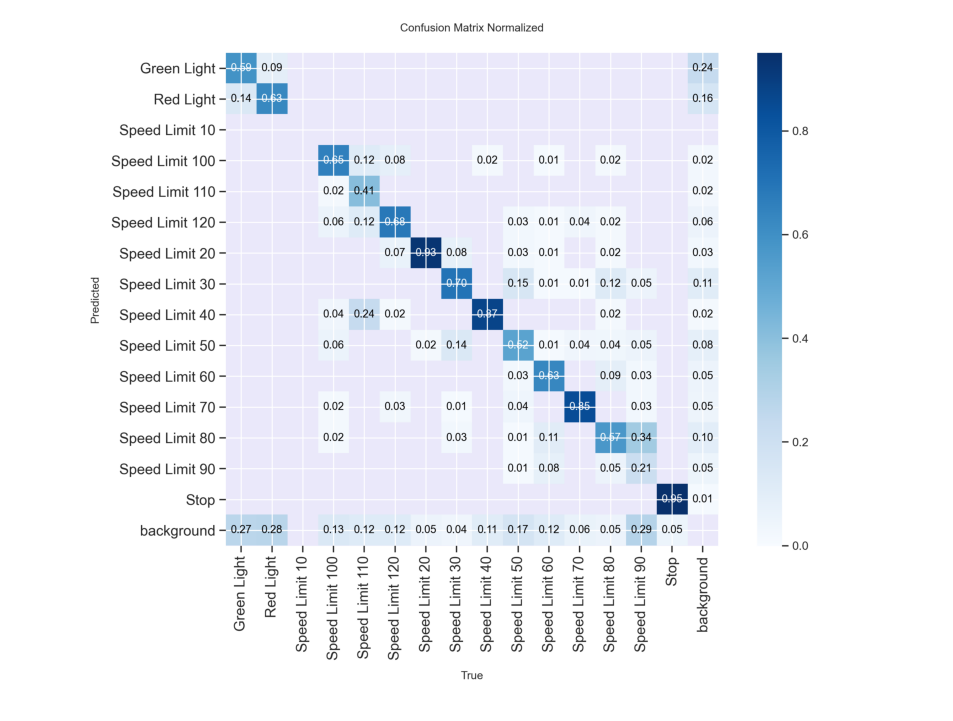

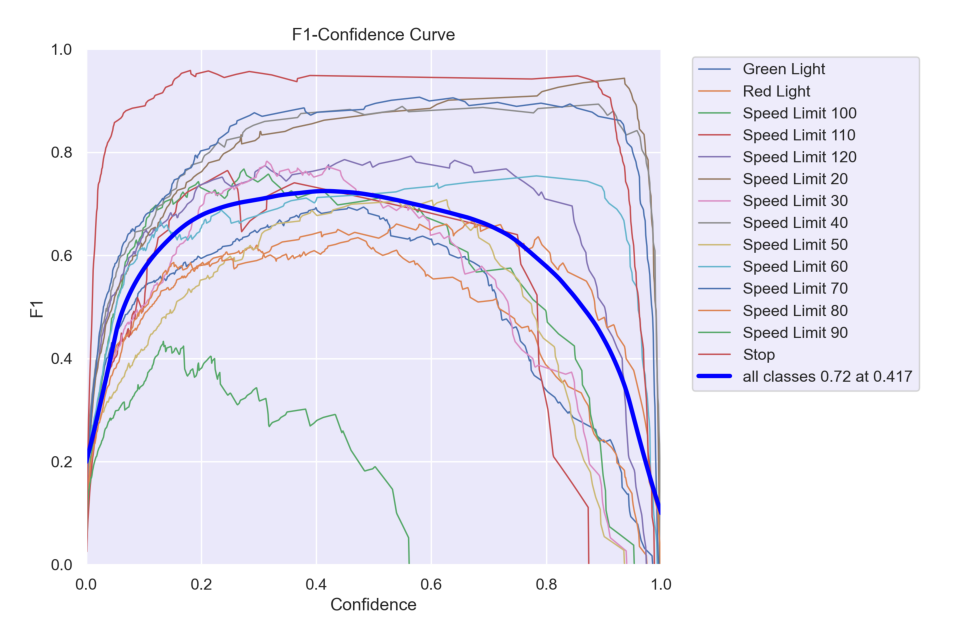

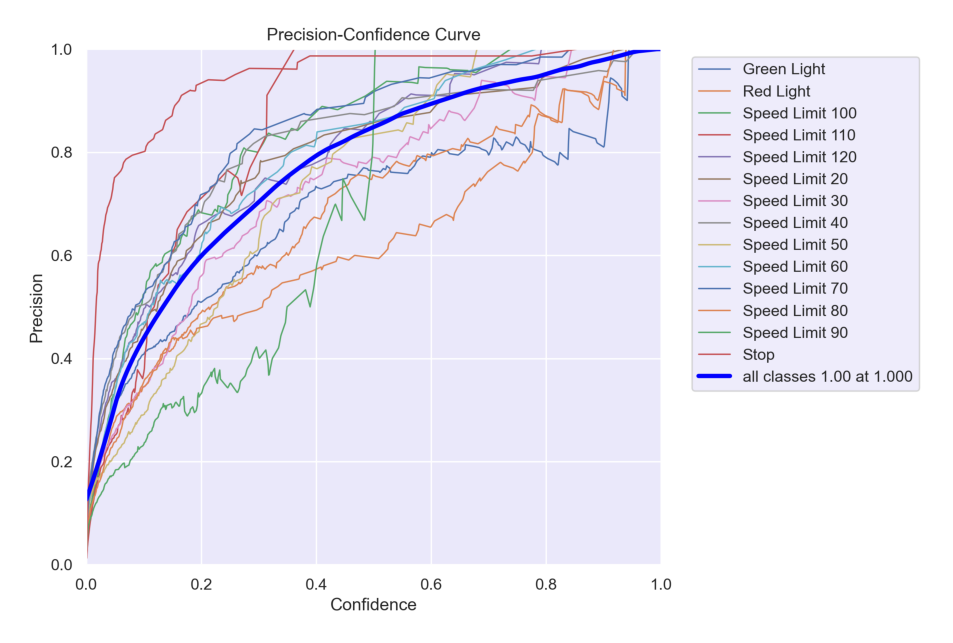

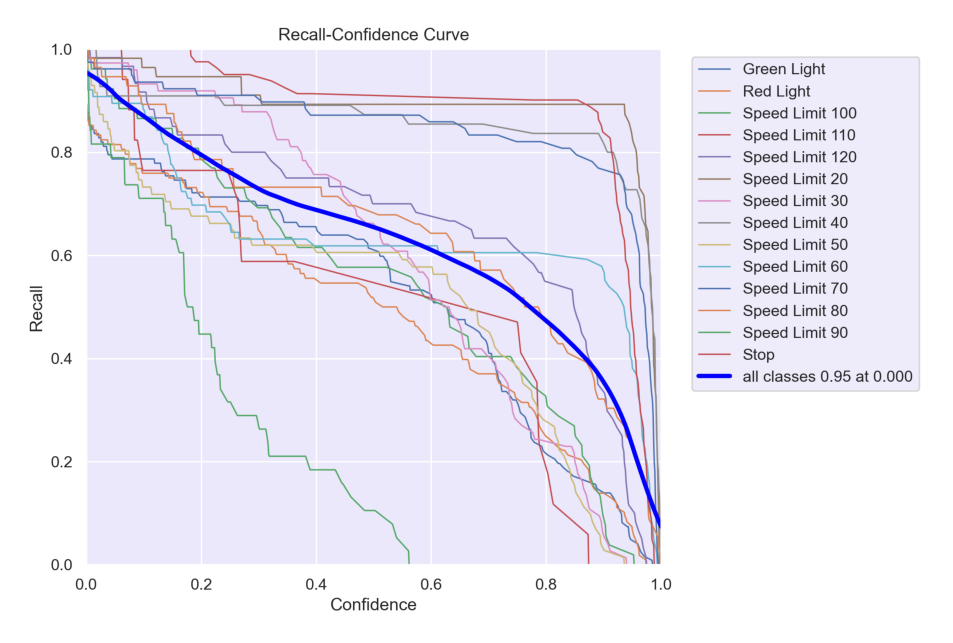

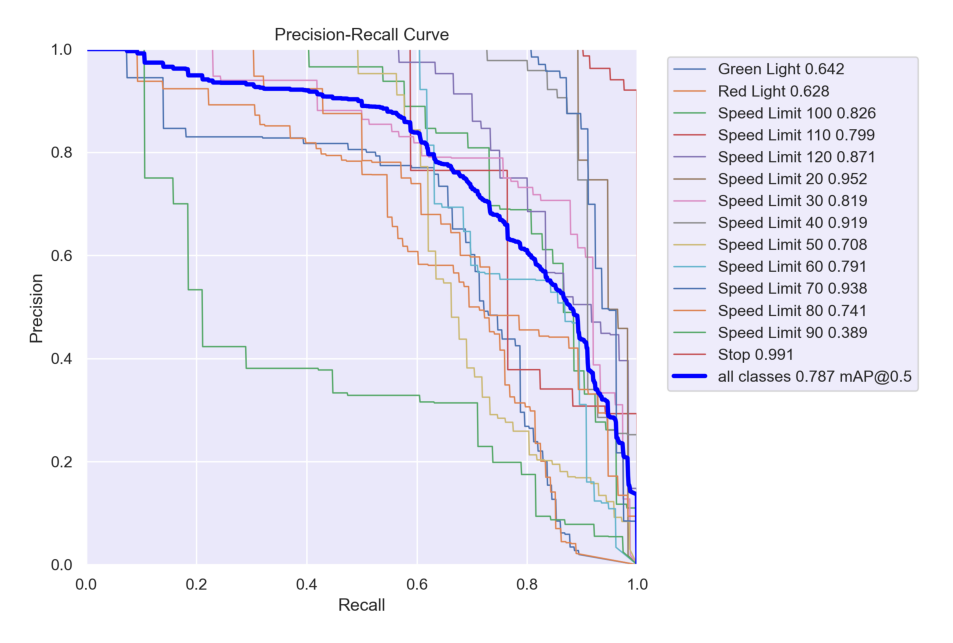

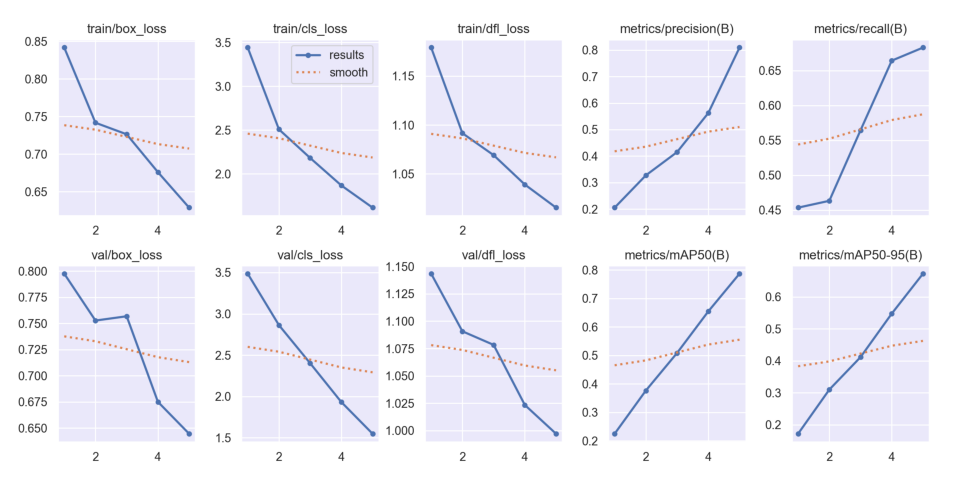

In [12]:
import os
import cv2
import matplotlib.pyplot as plt

def display_images(post_training_files_path, image_files):

    for image_file in image_files:
        image_path = os.path.join(post_training_files_path, image_file)
        img = cv2.imread(image_path)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        
        plt.figure(figsize=(10, 10), dpi=120)
        plt.imshow(img)
        plt.axis('off')
        plt.show()

image_files = [
    'confusion_matrix_normalized.png',
    'BoxF1_curve.png',
    'BoxP_curve.png',
    'BoxR_curve.png',
    'BoxPR_curve.png',
    'results.png'
]

post_training_files_path =r"C:\Users\Raul\runs\detect\train4"

display_images(post_training_files_path, image_files)

In [14]:
Result_Final_model = pd.read_csv(r"C:\Users\Raul\runs\detect\train4\results.csv")
Result_Final_model.tail(10)

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,1545.86,0.84161,3.44191,1.17904,0.20524,0.45354,0.22512,0.17188,0.79760,3.48603,1.14331,0.000175,0.000175,0.000175
1,2,3025.49,0.74168,2.50891,1.09156,0.32710,0.46332,0.37668,0.30992,0.75281,2.86349,1.09072,0.000281,0.000281,0.000281
2,3,4473.29,0.72632,2.18239,1.06913,0.41489,0.56441,0.50859,0.41151,0.75691,2.40230,1.07833,0.000317,0.000317,0.000317
3,4,5890.64,0.67603,1.86828,1.03909,0.56225,0.66413,0.65446,0.54763,0.67510,1.93173,1.02345,0.000214,0.000214,0.000214
4,5,7602.99,0.62880,1.61536,1.01548,0.80924,0.68280,0.78672,0.67246,0.64458,1.54862,0.99717,0.000109,0.000109,0.000109


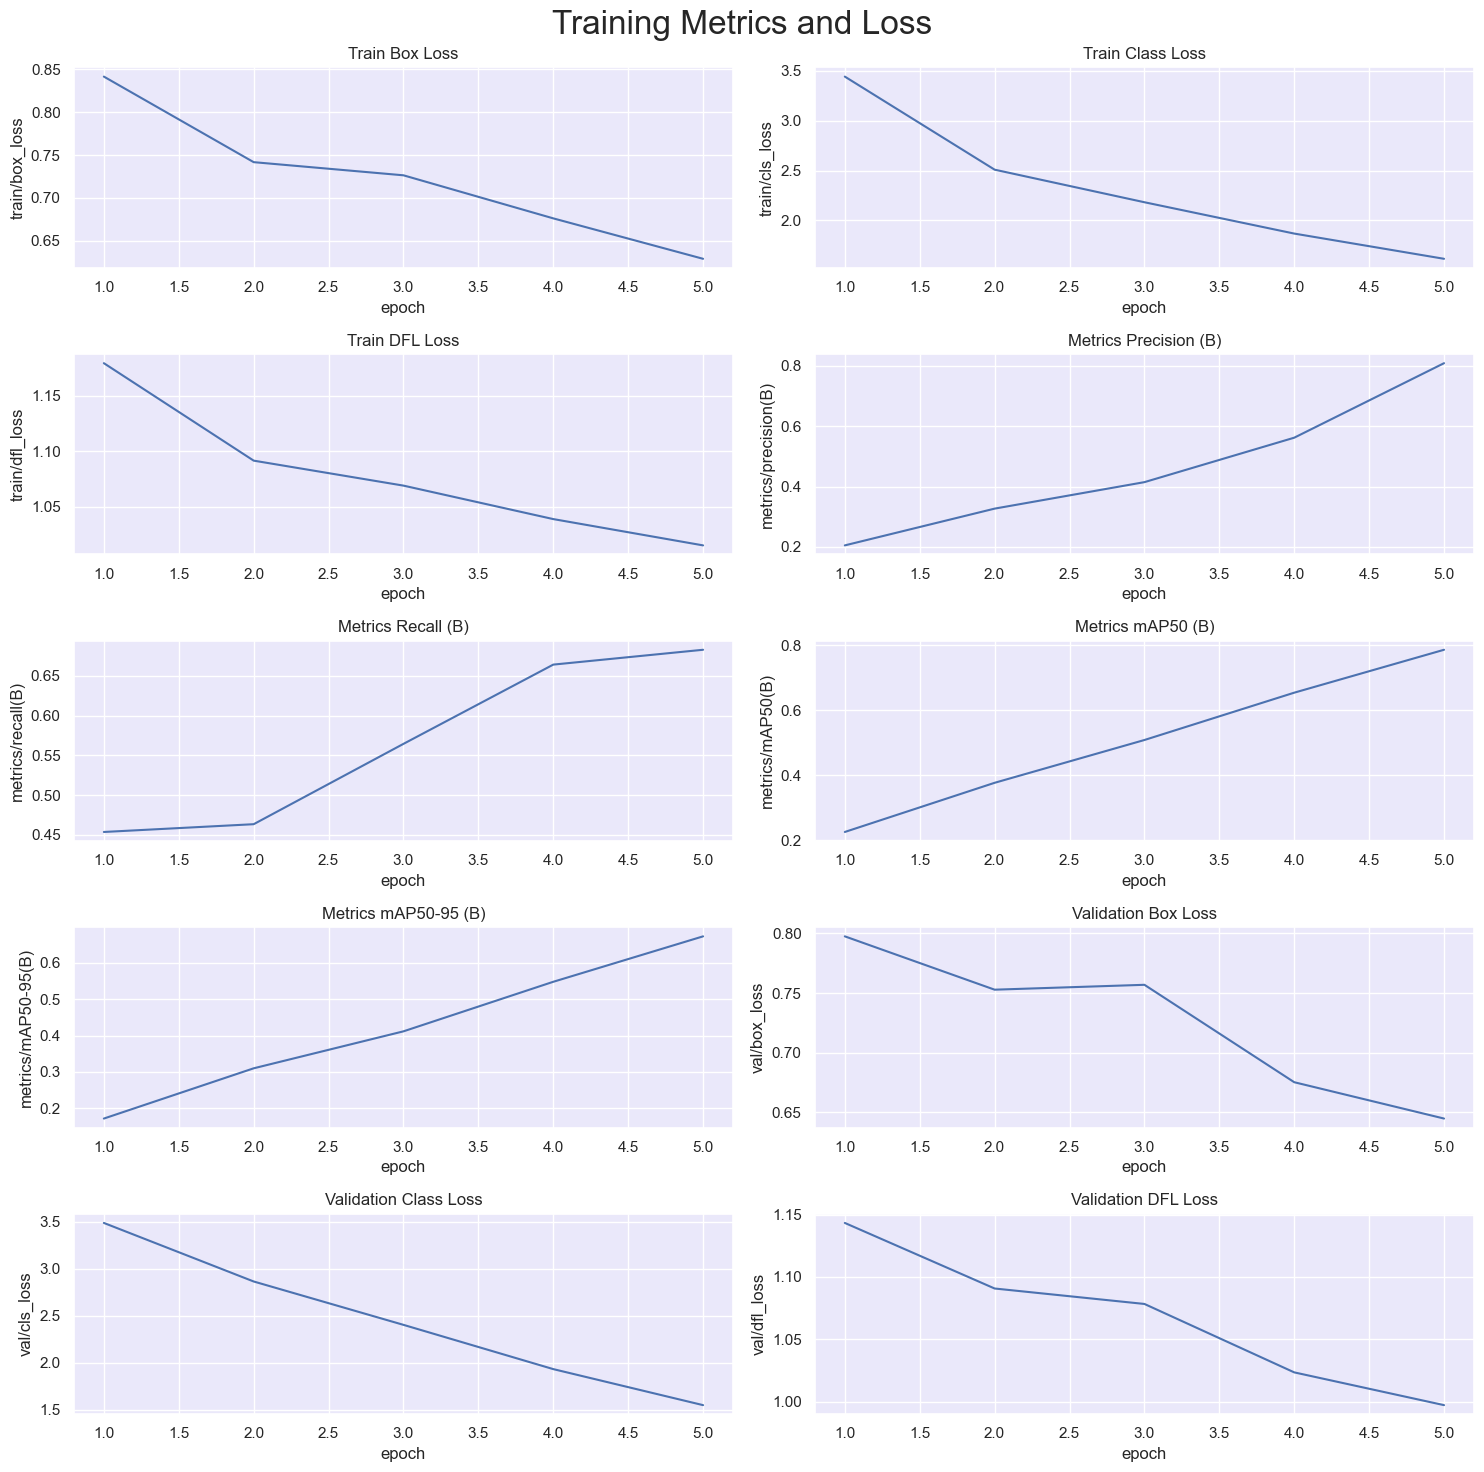

In [15]:
Result_Final_model.columns = Result_Final_model.columns.str.strip()

fig, axs = plt.subplots(nrows=5, ncols=2, figsize=(15, 15))

sns.lineplot(x='epoch', y='train/box_loss', data=Result_Final_model, ax=axs[0,0])
sns.lineplot(x='epoch', y='train/cls_loss', data=Result_Final_model, ax=axs[0,1])
sns.lineplot(x='epoch', y='train/dfl_loss', data=Result_Final_model, ax=axs[1,0])
sns.lineplot(x='epoch', y='metrics/precision(B)', data=Result_Final_model, ax=axs[1,1])
sns.lineplot(x='epoch', y='metrics/recall(B)', data=Result_Final_model, ax=axs[2,0])
sns.lineplot(x='epoch', y='metrics/mAP50(B)', data=Result_Final_model, ax=axs[2,1])
sns.lineplot(x='epoch', y='metrics/mAP50-95(B)', data=Result_Final_model, ax=axs[3,0])
sns.lineplot(x='epoch', y='val/box_loss', data=Result_Final_model, ax=axs[3,1])
sns.lineplot(x='epoch', y='val/cls_loss', data=Result_Final_model, ax=axs[4,0])
sns.lineplot(x='epoch', y='val/dfl_loss', data=Result_Final_model, ax=axs[4,1])

axs[0,0].set(title='Train Box Loss')
axs[0,1].set(title='Train Class Loss')
axs[1,0].set(title='Train DFL Loss')
axs[1,1].set(title='Metrics Precision (B)')
axs[2,0].set(title='Metrics Recall (B)')
axs[2,1].set(title='Metrics mAP50 (B)')
axs[3,0].set(title='Metrics mAP50-95 (B)')
axs[3,1].set(title='Validation Box Loss')
axs[4,0].set(title='Validation Class Loss')
axs[4,1].set(title='Validation DFL Loss')


plt.suptitle('Training Metrics and Loss', fontsize=24)
plt.subplots_adjust(top=0.8)
plt.tight_layout()
plt.show()

In [16]:
Valid_model = YOLO(r"C:\Users\Raul\runs\detect\train4\weights\best.pt")

metrics = Valid_model.val(split = 'val')

print("precision(B): ", metrics.results_dict["metrics/precision(B)"])
print("metrics/recall(B): ", metrics.results_dict["metrics/recall(B)"])
print("metrics/mAP50(B): ", metrics.results_dict["metrics/mAP50(B)"])
print("metrics/mAP50-95(B): ", metrics.results_dict["metrics/mAP50-95(B)"])

Ultralytics 8.3.227  Python-3.13.7 torch-2.9.0+cpu CPU (12th Gen Intel Core i7-1255U)
Model summary (fused): 72 layers, 3,008,573 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access  (ping: 0.10.1 ms, read: 92.867.4 MB/s, size: 18.7 KB)
val: Scanning C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\car\valid\labels.cache... 801 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 801/801 831.8Kit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 51/51 0.7it/s 1:121.6sss
                   all        801        944      0.808      0.683      0.787      0.672
           Green Light         87        122      0.733      0.639      0.642      0.344
             Red Light         74        108      0.698      0.546      0.628      0.347
       Speed Limit 100         52         52      0.887      0.605      0.826      0.744
       Speed Limit 110         17         17        


0: 640x640 (no detections), 179.4ms
Speed: 4.0ms preprocess, 179.4ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Speed Limit 20, 139.6ms
Speed: 4.5ms preprocess, 139.6ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Speed Limit 70, 145.4ms
Speed: 3.4ms preprocess, 145.4ms inference, 1.2ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 1 Stop, 116.6ms
Speed: 3.1ms preprocess, 116.6ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 Speed Limit 70s, 151.7ms
Speed: 3.4ms preprocess, 151.7ms inference, 1.5ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 2 Green Lights, 123.2ms
Speed: 5.1ms preprocess, 123.2ms inference, 1.4ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 (no detections), 133.6ms
Speed: 4.8ms preprocess, 133.6ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)

0: 640x640 (no detections), 129.0ms
Speed: 5.2ms preprocess,

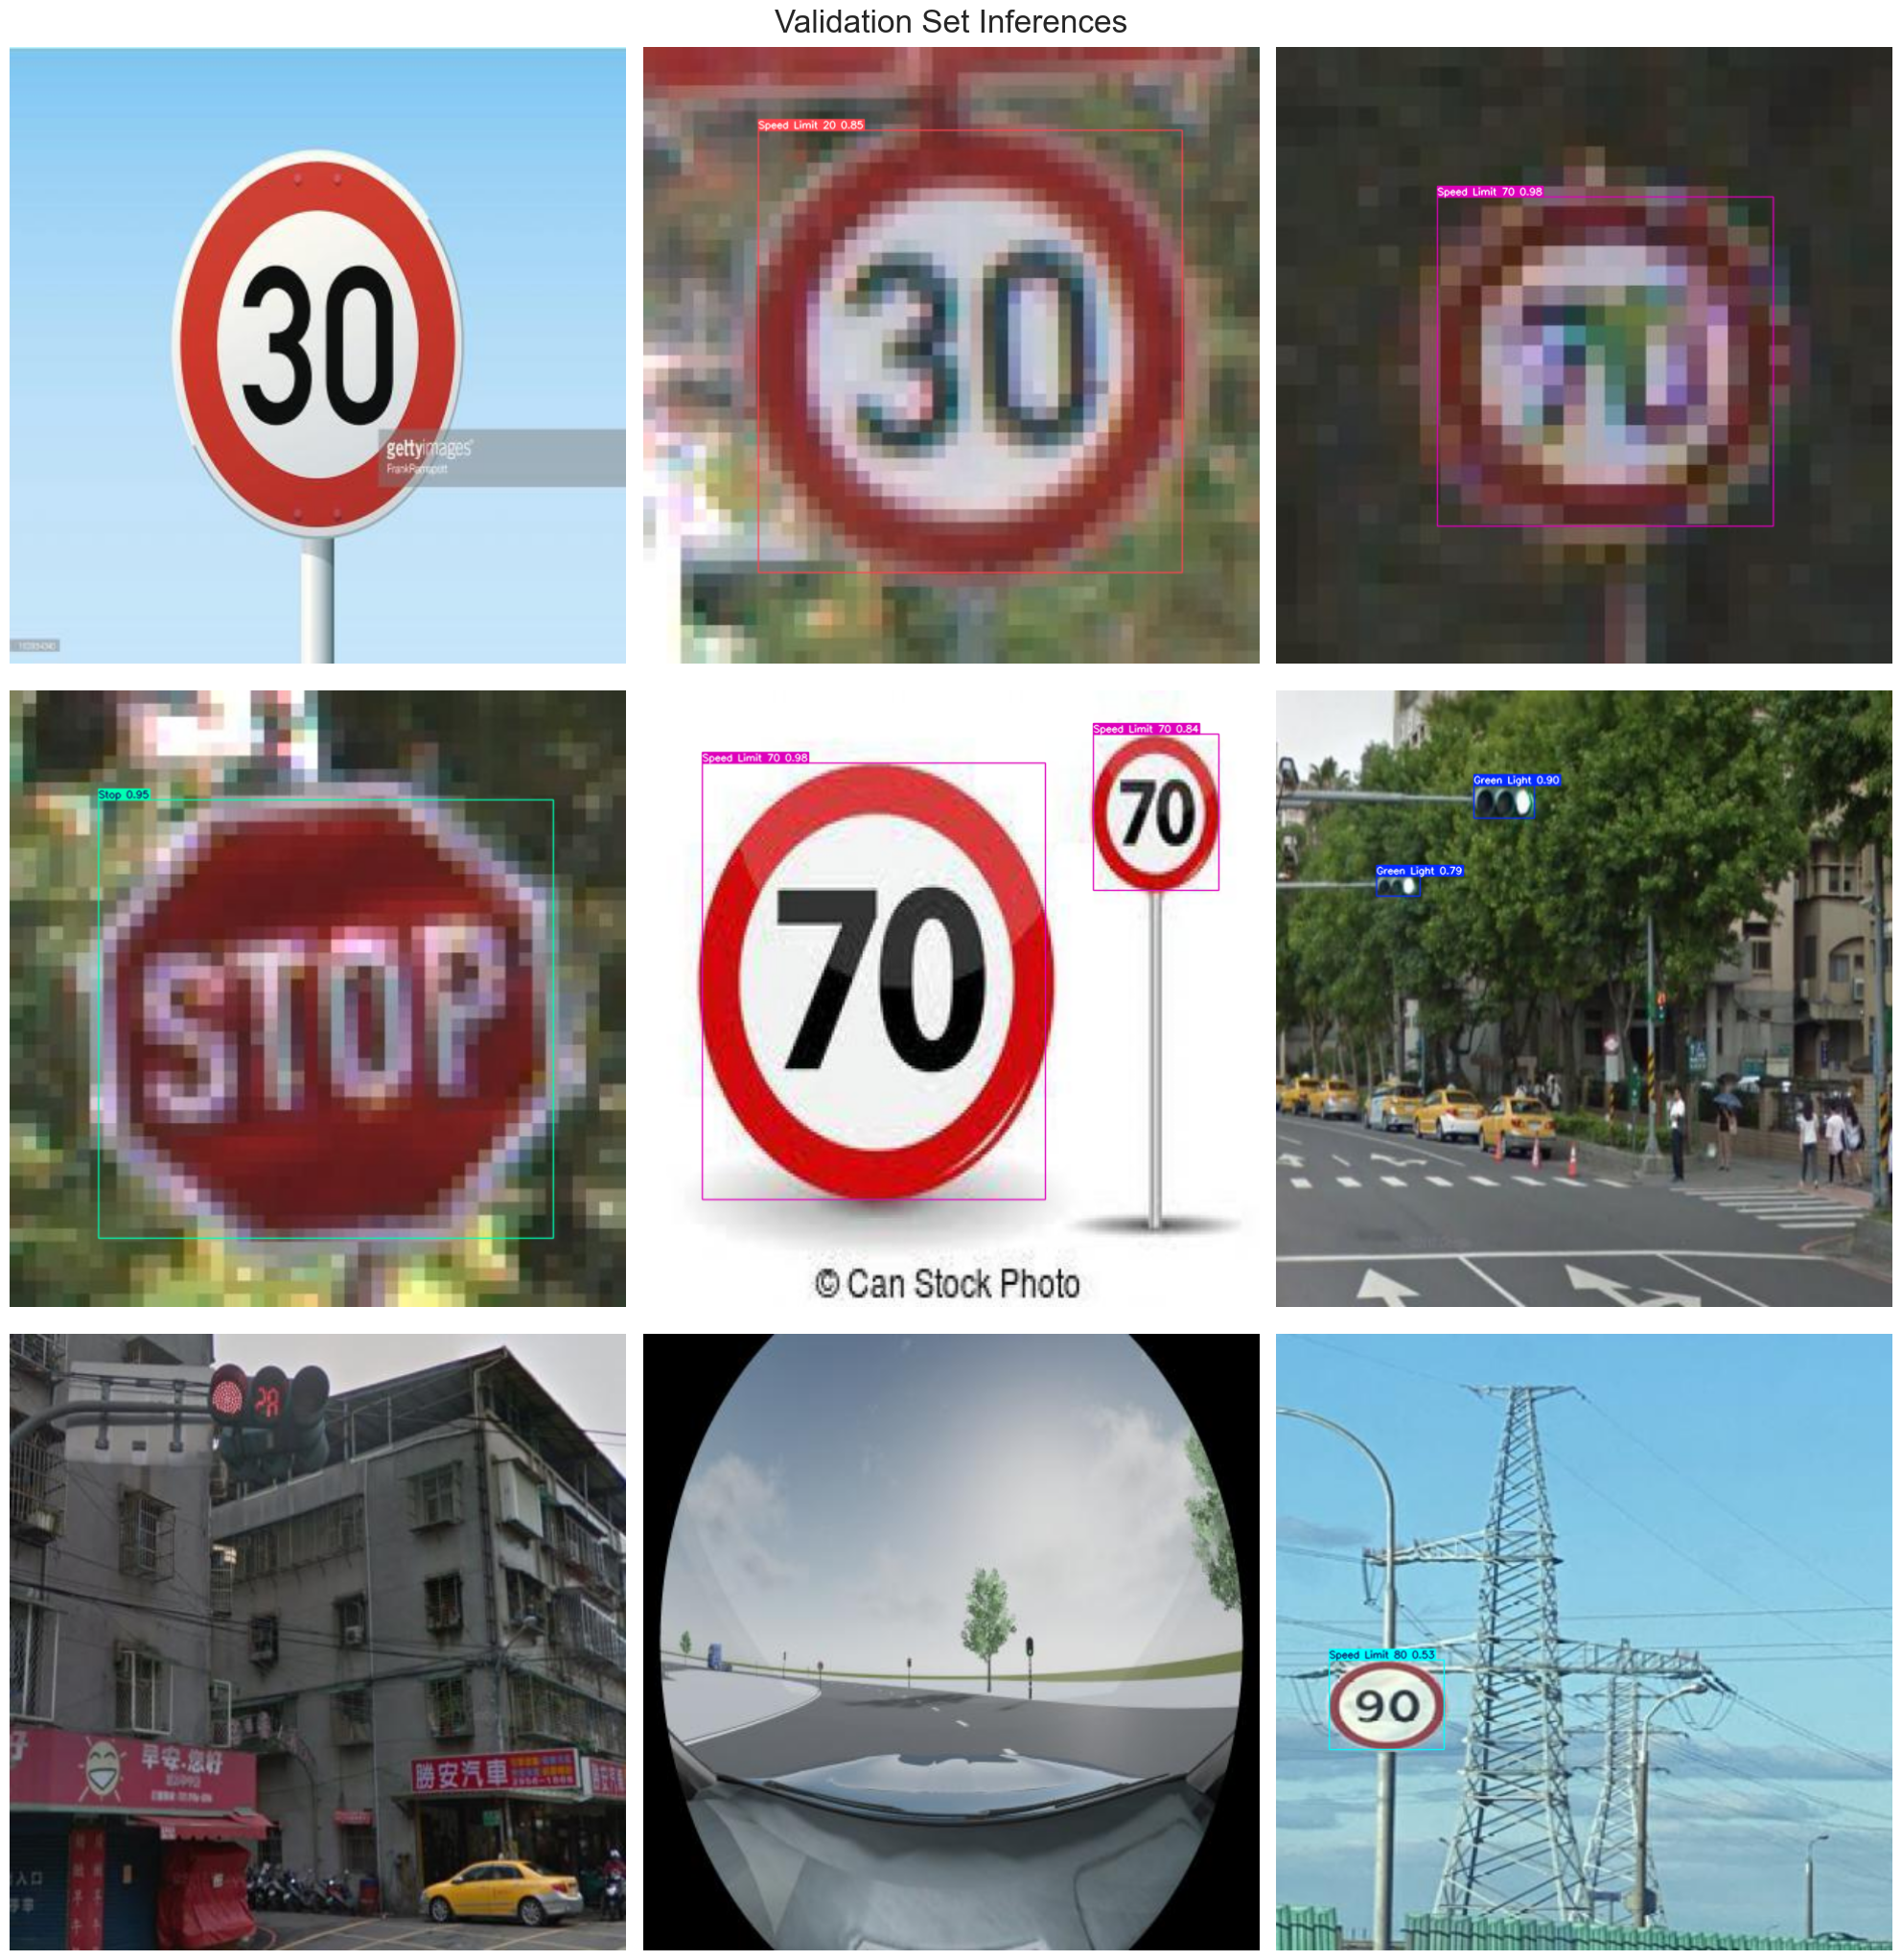

In [18]:
def normalize_image(image):
    return image / 255.0

def resize_image(image, size=(640, 640)):
    return cv2.resize(image, size)

dataset_path =r"C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\car"
valid_images_path = os.path.join(dataset_path, 'test', 'images')

image_files = [file for file in os.listdir(valid_images_path) if file.endswith('.jpg')]


if len(image_files) > 0:
    num_images = len(image_files)
    step_size = max(1, num_images // 9)  
    selected_images = [image_files[i] for i in range(0, num_images, step_size)]

    fig, axes = plt.subplots(3, 3, figsize=(20, 21))
    fig.suptitle('Validation Set Inferences', fontsize=24)

    for i, ax in enumerate(axes.flatten()):
        if i < len(selected_images):
            image_path = os.path.join(valid_images_path, selected_images[i])
            
            image = cv2.imread(image_path)
            
           
            if image is not None:
                
                resized_image = resize_image(image, size=(640, 640))
                
                normalized_image = normalize_image(resized_image)
                
               
                normalized_image_uint8 = (normalized_image * 255).astype(np.uint8)
                
                
                results = Valid_model.predict(source=normalized_image_uint8, imgsz=640, conf=0.5)
                
                
                annotated_image = results[0].plot(line_width=1)
                annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
                ax.imshow(annotated_image_rgb)
            else:
                print(f"Failed to load image {image_path}")
        ax.axis('off')

    plt.tight_layout()
    plt.show()

In [22]:
Valid_model.predict(source=r"C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\video.mp4", show=True,save = True)


WARNING 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/508) C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\video.mp4: 640x640 (no detections), 155.9ms
video 1/1 (frame 2/508) C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\video.mp4: 640x640 1 Stop, 129.2ms
video 1/1 (frame 3/508) C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\video.mp4: 640x640 (no 

[ultralytics.engine.results.Results object with attributes:
 
 boxes: ultralytics.engine.results.Boxes object
 keypoints: None
 masks: None
 names: {0: 'Green Light', 1: 'Red Light', 2: 'Speed Limit 10', 3: 'Speed Limit 100', 4: 'Speed Limit 110', 5: 'Speed Limit 120', 6: 'Speed Limit 20', 7: 'Speed Limit 30', 8: 'Speed Limit 40', 9: 'Speed Limit 50', 10: 'Speed Limit 60', 11: 'Speed Limit 70', 12: 'Speed Limit 80', 13: 'Speed Limit 90', 14: 'Stop'}
 obb: None
 orig_img: array([[[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
         [0, 0, 0],
         [0, 0, 0]],
 
        ...,
 
        [[0, 0, 0],
         [0, 0, 0],
         [0, 0, 0],
         ...,
         [0, 0, 0],
     

In [ ]:
from ultralytics import YOLO

model = YOLO("runs/detect/train4/weights/best.pt")  

source = r"C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\video.mp4"

results = model.predict(source=source, conf=0.25)

def decide_action(label):
    if label == "Red Light":
        return "STOP - semafor roșu"
    
    elif label == "Green Light":
        return "CONTINUĂ DEPLASAREA"
    
    elif label == "Stop":
        return "OPRIRE OBLIGATORIE"
    
    elif label.startswith("Speed Limit"):
        speed = label.split(" ")[-1]
        return f"SETARE VITEZĂ MAXIMĂ: {speed} km/h"
    
    else:
        return "Nicio acțiune"

for r in results:
    if r.boxes is not None:
        for box in r.boxes:
            class_id = int(box.cls[0])
            label = model.names[class_id]
            action = decide_action(label)
            print(f"Semn detectat: {label} → Acțiune: {action}")



WARNING 
inference results will accumulate in RAM unless `stream=True` is passed, causing potential out-of-memory
errors for large sources or long-running streams and videos. See https://docs.ultralytics.com/modes/predict/ for help.

Example:
    results = model(source=..., stream=True)  # generator of Results objects
    for r in results:
        boxes = r.boxes  # Boxes object for bbox outputs
        masks = r.masks  # Masks object for segment masks outputs
        probs = r.probs  # Class probabilities for classification outputs

video 1/1 (frame 1/508) C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\video.mp4: 640x640 (no detections), 160.7ms
video 1/1 (frame 2/508) C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\video.mp4: 640x640 1 Stop, 122.3ms
video 1/1 (frame 3/508) C:\Users\Raul\Desktop\Facultate\An 3\Proiect SBC\3 - Autonomous Car Navigation System\arhiva 1\video.mp4: 640x640 (no 